# Partición estratificada y balanceada de funciones de cita (70 / 15 / 15)

Este notebook parte el dataset etiquetado (`selected_function`) en **entrenamiento, validación y pruebas** de modo que, **incluyendo los datos sintéticos**, queden en **70 % / 15 % / 15 % del total**, con la **misma cantidad de citas por función de cita** en cada grupo.

**Reglas aplicadas**

1. Las citas anotadas manualmente (`annotator` distinto de `llm-ensemble`) van **solo a pruebas**.
2. Todas las citas de un documento (`citing_arxiv_id`) que tenga **al menos una cita manual** también van a pruebas.
3. **Tamaños:** la cuota por clase de pruebas es la de la clase más grande de esa población obligatoria; de ahí salen las cuotas de validación y entrenamiento que dan exactamente 70/15/15.
4. **Validación y entrenamiento:** las citas restantes se reparten por **documentos completos** y de forma estratificada (misma proporción 15:70 en cada clase).
5. Cada grupo se completa hasta su cuota con **datos sintéticos** generados solo desde las citas reales de ese mismo grupo usando un modelo BART.

Cada registro recibe los campos `origin` (`manual`, `doc_manual`, `real`, `synthetic`), `split`, y los sintéticos además `source_record_key` y `aug_method`, para poder filtrar los datos fabricados en cualquier evaluación.

In [1]:
import os
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import json, re, os, math, random, hashlib
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from transformers import BartForConditionalGeneration, BartTokenizer
import seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED)

DRIVE_DIR = "/content/drive/MyDrive/Colab Notebooks/proyecto"
INPUT_PATH = f"{DRIVE_DIR}/data/citations_labeled_v2.json"
OUTPUT_DIR = f"{DRIVE_DIR}/data"

LABEL_COL = "selected_function"
GROUP_COL = "citing_arxiv_id"
ANNOT_COL = "annotator"
AUTO_ANNOTATOR = "llm-ensemble"
TEXT_FIELDS = ("citing_sentence", "left_context", "right_context")

SPLIT_RATIOS = {"train": 0.70, "val": 0.15, "test": 0.15}
TEST_TARGET_PER_CLASS = None
assert abs(sum(SPLIT_RATIOS.values()) - 1) < 1e-9

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 1. Carga y exploración del dataset

Citas: 13243 | Documentos (citing_arxiv_id): 1570 | Funciones de cita: 9
Citas sin etiqueta: 0


,Citas,%
selected_function,,
Background,2193,16.56
Comparison,2128,16.07
Application,2106,15.90
Basis,1677,12.66
Evidence,1425,10.76
Further Reading,1408,10.63
Gap,935,7.06
Identification of the Originator,800,6.04
Improvement/Modification,571,4.31


,Citas
annotator,
llm-ensemble,12773
ca.torres,241
fredygamez,229


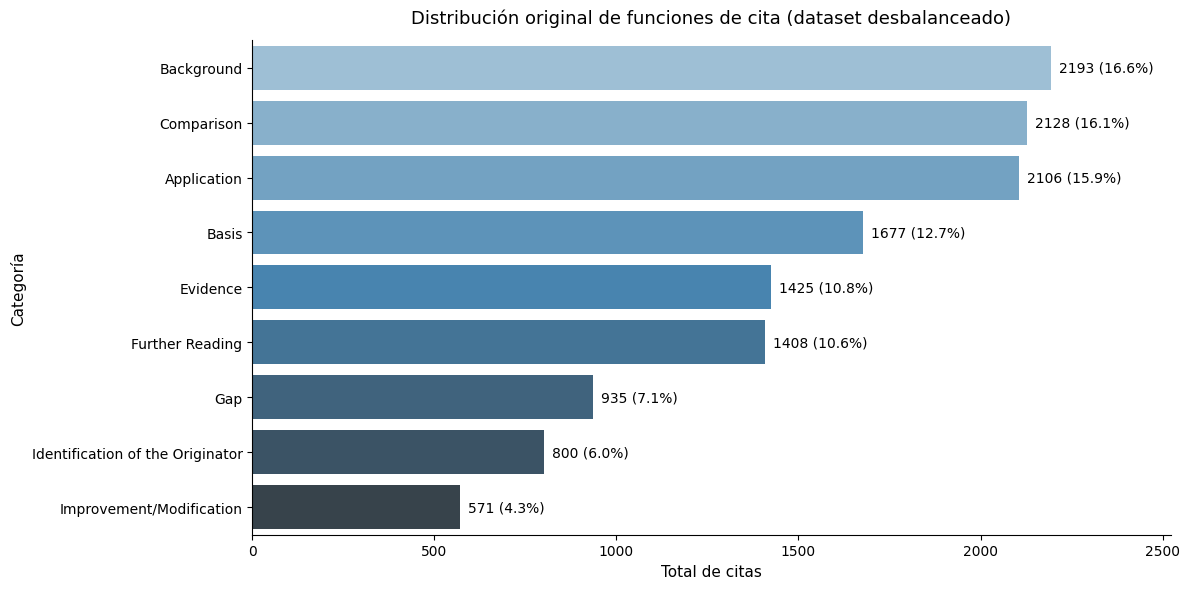

In [3]:
with open(INPUT_PATH, encoding="utf-8") as f:
    records = json.load(f)
df = pd.DataFrame(records)

LABELS = sorted(df[LABEL_COL].unique())
K = len(LABELS)
N = len(df)

print(f"Citas: {N} | Documentos (citing_arxiv_id): {df[GROUP_COL].nunique()} | Funciones de cita: {K}")
print(f"Citas sin etiqueta: {(df[LABEL_COL] == '').sum()}")

dist = df[LABEL_COL].value_counts().rename("Citas").to_frame()
dist["%"] = (dist["Citas"] / N * 100).round(2)
display(dist)

display(df[ANNOT_COL].value_counts().rename("Citas").to_frame())

df_cobertura = (dist.reset_index().rename(columns={LABEL_COL: "Categoría", "Citas": "Total"}).sort_values("Total", ascending=False))

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x="Total",
    y="Categoría",
    data=df_cobertura,
    palette="Blues_d",
    hue="Categoría",
    legend=False
)

max_val = df_cobertura["Total"].max()
for i, (_, row) in enumerate(df_cobertura.iterrows()):
    ax.text(row["Total"] + max_val * 0.01, i, f"{int(row['Total'])} ({row['%']:.1f}%)", va="center", fontsize=10)

ax.set_xlim(0, max_val * 1.15)
ax.set_title("Distribución original de funciones de cita (dataset desbalanceado)", fontsize=13, pad=12)
ax.set_xlabel("Total de citas", fontsize=11)
ax.set_ylabel("Categoría", fontsize=11)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

## 2. Citas manuales y documentos asociados

Se marcan las citas manuales y, con `citing_arxiv_id`, todas las citas de los documentos que tienen al menos una cita manual. Ese conjunto es la **población obligatoria de pruebas**.

In [4]:
df["is_manual"] = df[ANNOT_COL] != AUTO_ANNOTATOR
manual_docs = set(df.loc[df["is_manual"], GROUP_COL])
df["in_manual_doc"] = df[GROUP_COL].isin(manual_docs)
df["origin"] = np.where(df["is_manual"], "manual", np.where(df["in_manual_doc"], "doc_manual", "real"))

print(f"Citas manuales: {int(df['is_manual'].sum())}")
print(f"Documentos con al menos una cita manual: {len(manual_docs)} de {df[GROUP_COL].nunique()}")
print(f"Citas en esos documentos (población obligatoria de pruebas): {int(df['in_manual_doc'].sum())} ({df['in_manual_doc'].mean()*100:.1f}% del dataset)")
print(f"Citas restantes (candidatas a validación y entrenamiento): {int((~df['in_manual_doc']).sum())}")

tab = (df.pivot_table(index=LABEL_COL, columns="origin", values=GROUP_COL, aggfunc="count", fill_value=0).reindex(columns=["manual", "doc_manual", "real"], fill_value=0))
tab["Obligatorias en pruebas"] = tab["manual"] + tab["doc_manual"]
tab["Resto (val/train)"] = tab["real"]
display(tab)

Citas manuales: 470
Documentos con al menos una cita manual: 278 de 1570
Citas en esos documentos (población obligatoria de pruebas): 3719 (28.1% del dataset)
Citas restantes (candidatas a validación y entrenamiento): 9524


origin,manual,doc_manual,real,Obligatorias en pruebas,Resto (val/train)
selected_function,,,,,
Application,0,267,1839,267,1839
Background,0,517,1676,517,1676
Basis,0,440,1237,440,1237
Comparison,0,357,1771,357,1771
Evidence,179,353,893,532,893
Further Reading,93,579,736,672,736
Gap,86,267,582,353,582
Identification of the Originator,77,253,470,330,470
Improvement/Modification,35,216,320,251,320


## 3. Técnica de aumento de datos

Se utiliza el modelo **BART (`eugenesiow/bart-paraphrase`)** mediante la librería `transformers` para generar paráfrasis estructuradas de los ejemplos reales.

- Se aplica el aumento de datos a los 8 campos de texto principales: `left_context`, `citing_sentence`, `right_context`, `cited_title`, `cited_abstract`, `chunk_text1`, `chunk_text2` y `chunk_text3`.
- Se enmascara temporalmente el marcador `#CITATION_TAG` para evitar que el tokenizador lo elimine o deforme durante la inferencia.
- Los campos `cited_arxiv_id` y `cited_category` se dejan en blanco de forma explícita.
- El campo `annotator` se sobrescribe como `llm-augmentation`.
- Se genera un nuevo `record_key` único y se preserva el de origen en `source_record_key`.
- Cada sintético se genera **solo desde registros reales de su mismo grupo**, evitando cualquier tipo de contaminación de datos entre los conjuntos.

In [7]:
import torch
from transformers import BartForConditionalGeneration, BartTokenizer
from tqdm.auto import tqdm
import hashlib

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_name = 'eugenesiow/bart-paraphrase'
print(f"Cargando modelo {model_name} en {device}...")

tokenizer = BartTokenizer.from_pretrained(model_name)
model = BartForConditionalGeneration.from_pretrained(
    model_name,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32
).to(device)
model.eval()

def augment_batch_with_bart(texts, batch_size=64):
    results = list(texts)

    valid_indices = [
        i for i, t in enumerate(texts)
        if t and isinstance(t, str) and len(t.strip()) >= 10
    ]
    if not valid_indices:
        return results

    for start in range(0, len(valid_indices), batch_size):
        batch_idx = valid_indices[start:start + batch_size]
        batch_texts = [texts[i].replace("#CITATION_TAG", "CITATIONTAG") for i in batch_idx]

        inputs = tokenizer(
            batch_texts,
            return_tensors='pt',
            padding=True,
            truncation=True,
            max_length=256
        ).to(device)

        with torch.no_grad():
            generated_ids = model.generate(
                inputs['input_ids'],
                attention_mask=inputs['attention_mask'],
                max_new_tokens=256,
                num_beams=1,
                do_sample=True,
                temperature=0.9
            )

        decoded = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)
        for idx, out_text in zip(batch_idx, decoded):
            results[idx] = out_text.replace("CITATIONTAG", "#CITATION_TAG")

    return results

def synthesize(sources, n_needed, split, rng, batch_size=64):
    if n_needed <= 0:
        return []
    if not sources:
        raise ValueError(f"Sin registros fuente para sintetizar en {split}")

    pool = list(sources)
    rng.shuffle(pool)

    campos_a_aumentar = [
        "left_context", "citing_sentence", "right_context",
        "cited_title", "cited_abstract",
        "chunk_text1", "chunk_text2", "chunk_text3"
    ]
    campos_en_blanco = ["cited_arxiv_id", "cited_category"]

    out = []
    for k in range(n_needed):
        src = pool[k % len(pool)]
        new = dict(src)
        for campo in campos_en_blanco:
            new[campo] = ""
        new[ANNOT_COL] = "llm-augmentation"
        new["origin"] = "synthetic"
        new["source_record_key"] = src.get("record_key", "")
        new["aug_method"] = "bart-paraphrase"
        new["record_key"] = hashlib.sha1(
            f"{src.get('record_key', '')}|{split}|{k}|{SEED}".encode()
        ).hexdigest()[:16]
        out.append(new)

    tasks = []
    texts_to_process = []
    for rec_idx, rec in enumerate(out):
        for campo in campos_a_aumentar:
            val = rec.get(campo, "")
            if val and isinstance(val, str) and len(val.strip()) >= 10:
                tasks.append((rec_idx, campo))
                texts_to_process.append(val)

    label_name = sources[0].get(LABEL_COL, "")
    pbar_desc = f"[{split} - {label_name[:18]}] ({n_needed} regs)"

    for start in tqdm(range(0, len(texts_to_process), batch_size), desc=pbar_desc, leave=False):
        batch_texts = texts_to_process[start:start + batch_size]
        paraphrased = augment_batch_with_bart(batch_texts, batch_size=batch_size)
        for (rec_idx, campo), new_text in zip(tasks[start:start + batch_size], paraphrased):
            out[rec_idx][campo] = new_text

    print(f"[{split}] {label_name}: {n_needed} registros sintetizados.")
    return out

Cargando modelo eugenesiow/bart-paraphrase en cuda...


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

## 4. Cuotas por clase y grupo de pruebas


In [8]:
from fractions import Fraction

rng = random.Random(SEED)

test_idx = df.index[df["in_manual_doc"]].tolist()
test_real = [records[i] for i in test_idx]
for i in test_idx:
    records[i]["origin"] = df.at[i, "origin"]

test_counts = df.loc[test_idx, LABEL_COL].value_counts().reindex(LABELS, fill_value=0)

r_tr, r_va, r_te = (Fraction(str(SPLIT_RATIOS[k])) for k in ("train", "val", "test"))
Tc = int(test_counts.max())
if TEST_TARGET_PER_CLASS is not None:
    Tc = max(Tc, int(TEST_TARGET_PER_CLASS))
while not ((Tc * r_va / r_te).denominator == 1 and (Tc * r_tr / r_te).denominator == 1):
    Tc += 1
Vc = int(Tc * r_va / r_te)
Rc = int(Tc * r_tr / r_te)

print(f"Población obligatoria de pruebas: {len(test_idx)} citas = {len(test_idx)/N*100:.1f}% del dataset")
print(f"Clase más grande de esa población: {test_counts.idxmax()} ({int(test_counts.max())})")
print(f"Cuota por clase -> pruebas: {Tc} | validación: {Vc} | entrenamiento: {Rc}")
print(f"Tamaño final: {K*Tc} + {K*Vc} + {K*Rc} = {K*(Tc+Vc+Rc)} citas (train/val/test = {Rc/(Tc+Vc+Rc)*100:.0f}% / {Vc/(Tc+Vc+Rc)*100:.0f}% / {Tc/(Tc+Vc+Rc)*100:.0f}%)")

test_syn = []
by_label = defaultdict(list)
for r in test_real: by_label[r[LABEL_COL]].append(r)
for lab in LABELS:
    test_syn += synthesize(by_label[lab], Tc - len(by_label[lab]), "test", rng)

man_t = df.loc[test_idx]
res_test = pd.DataFrame({
    "Manuales": man_t[man_t["origin"] == "manual"][LABEL_COL].value_counts(),
    "Docs con manual": man_t[man_t["origin"] == "doc_manual"][LABEL_COL].value_counts(),
}).reindex(LABELS).fillna(0).astype(int)
res_test["Reales"] = res_test["Manuales"] + res_test["Docs con manual"]
res_test["Sintéticas añadidas"] = Tc - res_test["Reales"]
res_test["Total pruebas"] = Tc
res_test["Factor de aumento"] = (Tc / res_test["Reales"]).round(2)
display(res_test)
print(f"Pruebas: {len(test_real)} reales + {len(test_syn)} sintéticas = {len(test_real)+len(test_syn)}")

Población obligatoria de pruebas: 3719 citas = 28.1% del dataset
Clase más grande de esa población: Further Reading (672)
Cuota por clase -> pruebas: 672 | validación: 672 | entrenamiento: 3136
Tamaño final: 6048 + 6048 + 28224 = 40320 citas (train/val/test = 70% / 15% / 15%)


[test - Application] (405 regs):   0%|          | 0/51 [00:00<?, ?it/s]

[test] Application: 405 registros sintetizados.


[test - Background] (155 regs):   0%|          | 0/20 [00:00<?, ?it/s]

[test] Background: 155 registros sintetizados.


[test - Basis] (232 regs):   0%|          | 0/29 [00:00<?, ?it/s]

... (9 outputs left out)

[test - Improvement/Modifi] (421 regs):   0%|          | 0/53 [00:00<?, ?it/s]

[test] Improvement/Modification: 421 registros sintetizados.


,Manuales,Docs con manual,Reales,Sintéticas añadidas,Total pruebas,Factor de aumento
selected_function,,,,,,
Application,0,267,267,405,672,2.52
Background,0,517,517,155,672,1.30
Basis,0,440,440,232,672,1.53
Comparison,0,357,357,315,672,1.88
Evidence,179,353,532,140,672,1.26
Further Reading,93,579,672,0,672,1.00
Gap,86,267,353,319,672,1.90
Identification of the Originator,77,253,330,342,672,2.04
Improvement/Modification,35,216,251,421,672,2.68


Pruebas: 3719 reales + 2329 sintéticas = 6048
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## 5. Grupo de validación

Con las citas que **no** están en documentos con anotación manual se separa validación por **documentos completos** y de forma estratificada:

1. Cada clase aporta a validación la proporción `val / (val + train)` = 15/85 de sus citas reales restantes.
2. Los documentos se ordenan priorizando los que aportan citas de clases raras, y se agrega cada documento solo si no supera la cuota real de ninguna clase.
3. Cada clase de validación se completa hasta `Vc` con sintéticos generados desde las citas reales de validación de esa clase.

In [9]:
rest_idx = df.index[~df["in_manual_doc"]].tolist()
rest = df.loc[rest_idx]
for i in rest_idx:
    records[i]["origin"] = "real"

rest_counts = rest[LABEL_COL].value_counts().reindex(LABELS, fill_value=0)
share_val = float(r_va / (r_va + r_tr))
quota_real_val = {l: int(round(share_val * rest_counts[l])) for l in LABELS}
assert all(quota_real_val[l] <= Vc for l in LABELS), "La cuota real de validación supera Vc"
print(f"Citas disponibles para val/train: {len(rest)} | proporción real a validación por clase: {share_val*100:.1f}%")

doc_labels = rest.groupby(GROUP_COL)[LABEL_COL].apply(list).to_dict()
freq = rest_counts.to_dict()
rng_val = random.Random(SEED)
order = sorted(doc_labels, key=lambda d_: -(sum(1 / freq[l] for l in doc_labels[d_]) + rng_val.random() * 1e-6))

cnt = Counter(); val_docs = []
for dk in order:
    c = Counter(doc_labels[dk])
    if all(cnt[l] + n <= quota_real_val[l] for l, n in c.items()):
        val_docs.append(dk); cnt.update(c)

val_docs = set(val_docs)
val_idx = rest.index[rest[GROUP_COL].isin(val_docs)].tolist()
val_real = [records[i] for i in val_idx]

by_label = defaultdict(list)
for r in val_real: by_label[r[LABEL_COL]].append(r)
rng = random.Random(SEED + 1)
val_syn = []
for lab in LABELS:
    val_syn += synthesize(by_label[lab], Vc - len(by_label[lab]), "val", rng)

res_val = pd.DataFrame({"Cuota real": pd.Series(quota_real_val),
                        "Reales (documentos completos)": [len(by_label[l]) for l in LABELS]}, index=LABELS)
res_val["Sintéticas añadidas"] = Vc - res_val["Reales (documentos completos)"]
res_val["Total validación"] = Vc
res_val["Factor de aumento"] = (Vc / res_val["Reales (documentos completos)"]).round(2)
display(res_val)
print(f"Validación: {len(val_docs)} documentos | {len(val_real)} reales + {len(val_syn)} sintéticas = {len(val_real)+len(val_syn)}")

Citas disponibles para val/train: 9524 | proporción real a validación por clase: 17.6%


[val - Application] (347 regs):   0%|          | 0/43 [00:00<?, ?it/s]

[val] Application: 347 registros sintetizados.


[val - Background] (376 regs):   0%|          | 0/46 [00:00<?, ?it/s]

[val] Background: 376 registros sintetizados.


[val - Basis] (454 regs):   0%|          | 0/57 [00:00<?, ?it/s]

... (11 outputs left out)

[val - Improvement/Modifi] (616 regs):   0%|          | 0/77 [00:00<?, ?it/s]

[val] Improvement/Modification: 616 registros sintetizados.


,Cuota real,Reales (documentos completos),Sintéticas añadidas,Total validación,Factor de aumento
Application,325,325,347,672,2.07
Background,296,296,376,672,2.27
Basis,218,218,454,672,3.08
Comparison,313,313,359,672,2.15
Evidence,158,158,514,672,4.25
Further Reading,130,130,542,672,5.17
Gap,103,103,569,672,6.52
Identification of the Originator,83,83,589,672,8.10
Improvement/Modification,56,56,616,672,12.00


Validación: 108 documentos | 1682 reales + 4366 sintéticas = 6048


## 6. Grupo de entrenamiento

Entrenamiento recibe todas las citas reales restantes y se completa con el aumento de datos hasta la cuota `Rc` de cada clase.

In [10]:
val_set = set(val_idx)
train_idx = [i for i in rest_idx if i not in val_set]
train_real = [records[i] for i in train_idx]

tr_counts = df.loc[train_idx, LABEL_COL].value_counts().reindex(LABELS, fill_value=0)
assert int(tr_counts.max()) <= Rc, "Hay más citas reales de entrenamiento que la cuota Rc"
print(f"Citas reales de entrenamiento: {len(train_real)} | Cuota por clase: {Rc}")

by_label = defaultdict(list)
for r in train_real: by_label[r[LABEL_COL]].append(r)
rng = random.Random(SEED + 2)
train_syn = []
for lab in LABELS:
    train_syn += synthesize(by_label[lab], Rc - len(by_label[lab]), "train", rng)

res_tr = pd.DataFrame({"Reales": tr_counts})
res_tr["Sintéticas añadidas"] = Rc - res_tr["Reales"]
res_tr["Total entrenamiento"] = Rc
res_tr["Factor de aumento"] = (Rc / res_tr["Reales"]).round(2)
display(res_tr)
print(f"Entrenamiento: {len(train_real)} reales + {len(train_syn)} sintéticas = {len(train_real)+len(train_syn)}")


Citas reales de entrenamiento: 7842 | Cuota por clase: 3136


[train - Application] (1622 regs):   0%|          | 0/201 [00:00<?, ?it/s]

[train] Application: 1622 registros sintetizados.


[train - Background] (1756 regs):   0%|          | 0/216 [00:00<?, ?it/s]

[train] Background: 1756 registros sintetizados.


[train - Basis] (2117 regs):   0%|          | 0/263 [00:00<?, ?it/s]

... (11 outputs left out)

[train - Improvement/Modifi] (2872 regs):   0%|          | 0/356 [00:00<?, ?it/s]

[train] Improvement/Modification: 2872 registros sintetizados.


,Reales,Sintéticas añadidas,Total entrenamiento,Factor de aumento
selected_function,,,,
Application,1514,1622,3136,2.07
Background,1380,1756,3136,2.27
Basis,1019,2117,3136,3.08
Comparison,1458,1678,3136,2.15
Evidence,735,2401,3136,4.27
Further Reading,606,2530,3136,5.17
Gap,479,2657,3136,6.55
Identification of the Originator,387,2749,3136,8.10
Improvement/Modification,264,2872,3136,11.88


Entrenamiento: 7842 reales + 20382 sintéticas = 28224


## 7. Datos balanceados finales

split,train,val,test
selected_function,,,
Application,3136,672,672
Background,3136,672,672
Basis,3136,672,672
Comparison,3136,672,672
Evidence,3136,672,672
Further Reading,3136,672,672
Gap,3136,672,672
Identification of the Originator,3136,672,672
Improvement/Modification,3136,672,672


Porcentaje de cada grupo sobre el total (incluidos los sintéticos):


split,train,val,test
% del total,70.0,15.0,15.0


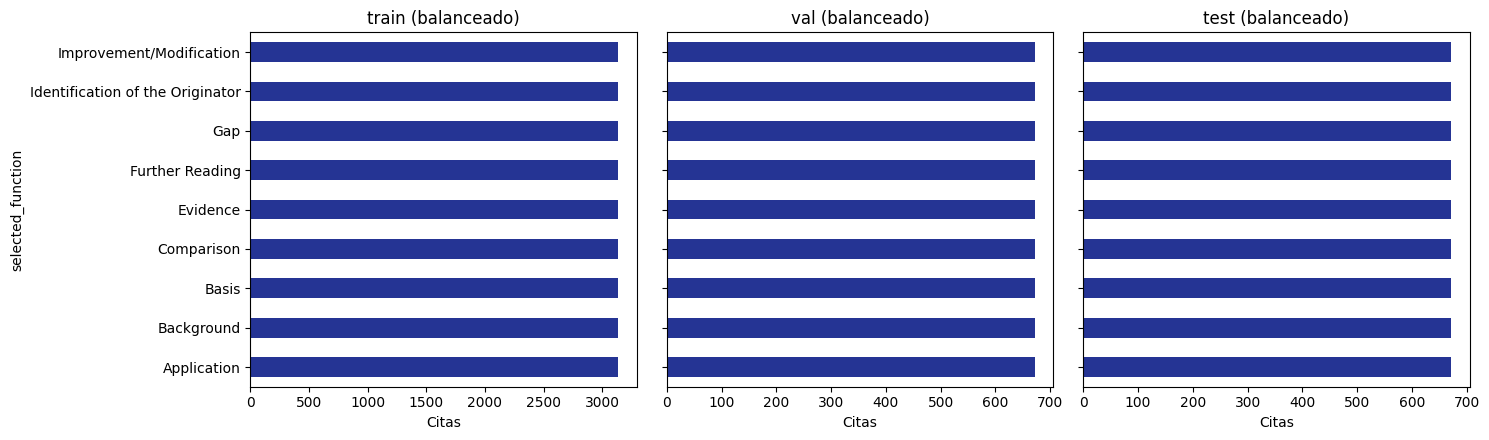

In [ ]:
splits = {
    "train": train_real + train_syn,
    "val": val_real + val_syn,
    "test": test_real + test_syn,
}
for name, recs in splits.items():
    for r in recs:
        r["split"] = name

final = pd.DataFrame([{
    "record_key": r["record_key"], GROUP_COL: r[GROUP_COL], LABEL_COL: r[LABEL_COL], ANNOT_COL: r[ANNOT_COL], "origin": r["origin"], "split": r["split"],
    "source_record_key": r.get("source_record_key", ""),
    "sentence": r["citing_sentence"],
} for recs in splits.values() for r in recs])

bal = final.pivot_table(index=LABEL_COL, columns="split", values="record_key", aggfunc="count", fill_value=0)[["train", "val", "test"]]
bal.loc["TOTAL"] = bal.sum()
display(bal)

pct_total = (bal.loc["TOTAL"] / bal.loc["TOTAL"].sum() * 100).round(2)
print("Porcentaje de cada grupo sobre el total (incluidos los sintéticos):")
display(pct_total.rename("% del total").to_frame().T)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, name in zip(axes, ["train", "val", "test"]):
    bal.drop(index="TOTAL")[name].sort_values().plot.barh(ax=ax, color="#253494")
    ax.set_title(f"{name} (balanceado)"); ax.set_xlabel("Citas")
plt.tight_layout(); plt.show()

## 8. Estadísticas: ubicación de los datos manuales y los fabricados

### 8.1 Composición de cada grupo por origen del dato

In [12]:
ORIGINS = ["manual", "doc_manual", "real", "synthetic"]
comp = final.pivot_table(index="split", columns="origin", values="record_key", aggfunc="count", fill_value=0)
comp = comp.reindex(index=["train", "val", "test"], columns=ORIGINS, fill_value=0)
comp["Total"] = comp.sum(axis=1)
comp_pct = (comp[ORIGINS].div(comp["Total"], axis=0) * 100).round(1).add_suffix(" %")
display(pd.concat([comp, comp_pct], axis=1))

real_total = int((final["origin"] != "synthetic").sum())
real_share = (final[final["origin"] != "synthetic"].groupby("split").size() / real_total * 100).round(1)
print("Reparto de las citas REALES (sin sintéticas) entre grupos:")
display(real_share.reindex(["train", "val", "test"]).rename("% de citas reales").to_frame())
print("Con los sintéticos, los grupos suman 70% / 15% / 15% del total; la tabla anterior muestra el reparto de lo real.")

origin,manual,doc_manual,real,synthetic,Total,manual %,doc_manual %,real %,synthetic %
split,,,,,,,,,
train,0,0,7842,20382,28224,0.0,0.0,27.8,72.2
val,0,0,1682,4366,6048,0.0,0.0,27.8,72.2
test,470,3249,0,2329,6048,7.8,53.7,0.0,38.5


Reparto de las citas REALES (sin sintéticas) entre grupos:


,% de citas reales
split,
train,59.2
val,12.7
test,28.1


Con los sintéticos, los grupos suman 70% / 15% / 15% del total; la tabla anterior muestra el reparto de lo real.


### 8.2 Datos manuales: ubicación por anotador y clase

split,train,val,test
annotator,,,
ca.torres,0,0,241
fredygamez,0,0,229


,Manuales en pruebas,Docs con manual (reales),Sintéticas,Total pruebas,% manuales
Application,0,267,405,672,0.0
Background,0,517,155,672,0.0
Basis,0,440,232,672,0.0
Comparison,0,357,315,672,0.0
Evidence,179,353,140,672,26.6
Further Reading,93,579,0,672,13.8
Gap,86,267,319,672,12.8
Identification of the Originator,77,253,342,672,11.5
Improvement/Modification,35,216,421,672,5.2


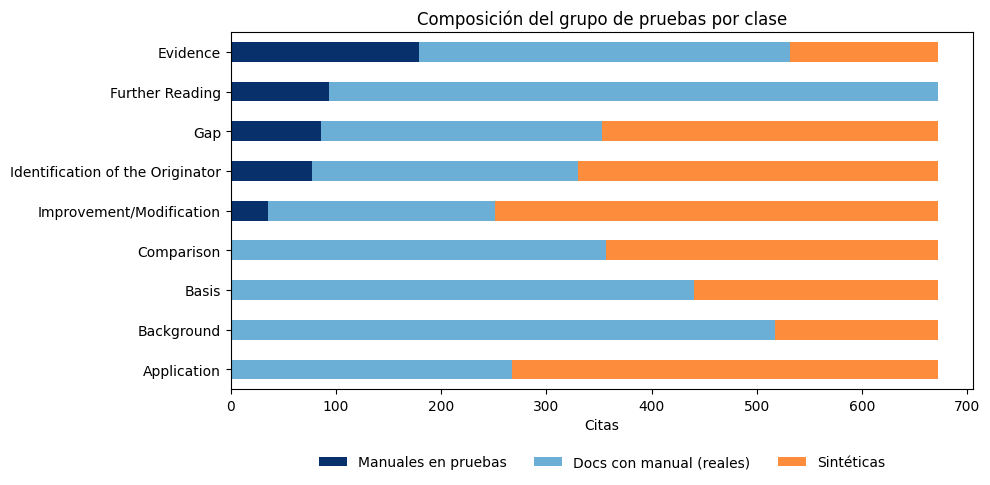

In [ ]:
manual_final = final[final["origin"] == "manual"]
display(manual_final.pivot_table(index=ANNOT_COL, columns="split", values="record_key", aggfunc="count", fill_value=0)
        .reindex(columns=["train", "val", "test"], fill_value=0))

man_cls = pd.DataFrame(index=LABELS)
man_cls["Manuales en pruebas"] = manual_final.groupby(LABEL_COL).size()
man_cls["Docs con manual (reales)"] = final[(final["origin"] == "doc_manual")].groupby(LABEL_COL).size()
man_cls["Sintéticas"] = final[(final["origin"] == "synthetic") & (final["split"] == "test")].groupby(LABEL_COL).size()
man_cls = man_cls.fillna(0).astype(int)
man_cls["Total pruebas"] = man_cls.sum(axis=1)
man_cls["% manuales"] = (man_cls["Manuales en pruebas"] / man_cls["Total pruebas"] * 100).round(1)
display(man_cls)

ax = man_cls[["Manuales en pruebas", "Docs con manual (reales)", "Sintéticas"]].sort_values("Manuales en pruebas").plot.barh(stacked=True, figsize=(10, 5), color=["#08306b", "#6baed6", "#fd8d3c"])
ax.set_title("Composición del grupo de pruebas por clase"); ax.set_xlabel("Citas")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
plt.tight_layout(); plt.show()

### 8.3 Datos fabricados: por grupo y clase

split,train,val,test,Total sintéticas
selected_function,,,,
Application,1622,347,405,2374
Background,1756,376,155,2287
Basis,2117,454,232,2803
Comparison,1678,359,315,2352
Evidence,2401,514,140,3055
Further Reading,2530,542,0,3072
Gap,2657,569,319,3545
Identification of the Originator,2749,589,342,3680
Improvement/Modification,2872,616,421,3909


Porcentaje de cada clase que es sintético:


split,train %,val %,test %
selected_function,,,
Application,51.7,51.6,60.3
Background,56.0,56.0,23.1
Basis,67.5,67.6,34.5
Comparison,53.5,53.4,46.9
Evidence,76.6,76.5,20.8
Further Reading,80.7,80.7,0.0
Gap,84.7,84.7,47.5
Identification of the Originator,87.7,87.6,50.9
Improvement/Modification,91.6,91.7,62.6


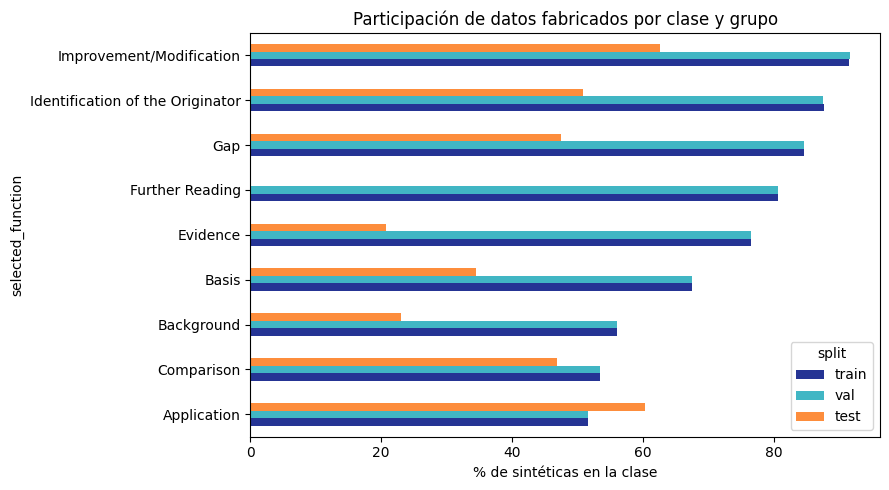

In [14]:
syn = final[final["origin"] == "synthetic"]
syn_tab = syn.pivot_table(index=LABEL_COL, columns="split", values="record_key", aggfunc="count", fill_value=0)
syn_tab = syn_tab.reindex(index=LABELS, columns=["train", "val", "test"], fill_value=0)
syn_tab["Total sintéticas"] = syn_tab.sum(axis=1)
display(syn_tab)

share = (syn.pivot_table(index=LABEL_COL, columns="split", values="record_key", aggfunc="count", fill_value=0)
         .reindex(index=LABELS, columns=["train", "val", "test"], fill_value=0)
         / bal.drop(index="TOTAL")[["train", "val", "test"]] * 100).round(1)
print("Porcentaje de cada clase que es sintético:")
display(share.add_suffix(" %"))

fig, ax = plt.subplots(figsize=(9, 5))
share.sort_values("train").plot.barh(ax=ax, color=["#253494", "#41b6c4", "#fd8d3c"])
ax.set_xlabel("% de sintéticas en la clase"); ax.set_title("Participación de datos fabricados por clase y grupo")
plt.tight_layout(); plt.show()

### 8.4 Calidad de los datos fabricados

,sintéticas,jaccard_medio,palabras_medias,palabras_fuente,pct_oración_modificada
split,,,,,
train,20382,0.76,25.50,26.63,94.28
val,4366,0.73,27.16,28.87,94.87
test,2329,0.76,26.16,27.35,93.47


Palabras medias de las oraciones reales por grupo:


,palabras
split,
train,26.90
val,29.11
test,27.70


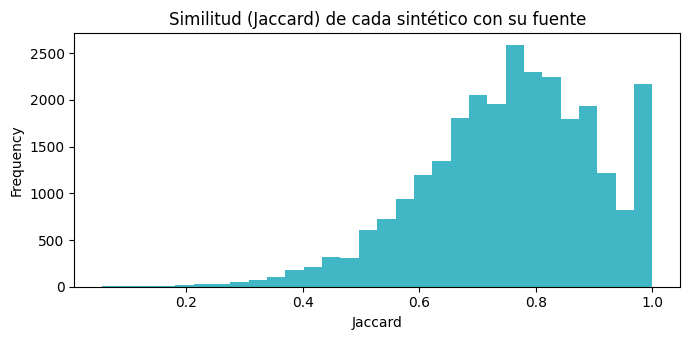

In [ ]:
src_text = {r["record_key"]: r["citing_sentence"] for r in records}
rows = []
for name in ["train", "val", "test"]:
    for r in splits[name]:
        if r["origin"] != "synthetic": continue
        a = set(src_text[r["source_record_key"]].lower().split()); b = set(r["citing_sentence"].lower().split())
        rows.append({"split": name, "jaccard": len(a & b) / max(1, len(a | b)),
                     "palabras": len(r["citing_sentence"].split()),
                     "palabras_fuente": len(src_text[r["source_record_key"]].split()),
                     "cambia_oracion": r["citing_sentence"] != src_text[r["source_record_key"]]})
q = pd.DataFrame(rows)
cal = q.groupby("split").agg(sintéticas=("jaccard", "size"), jaccard_medio=("jaccard", "mean"), palabras_medias=("palabras", "mean"), palabras_fuente=("palabras_fuente", "mean"), pct_oración_modificada=("cambia_oracion", lambda s: s.mean() * 100)).round(2)
display(cal.reindex(["train", "val", "test"]))

real_len = final[final["origin"] != "synthetic"].assign(palabras=lambda x: x["sentence"].str.split().str.len()).groupby("split")["palabras"].mean().round(2)
print("Palabras medias de las oraciones reales por grupo:"); display(real_len.reindex(["train", "val", "test"]).to_frame())

fig, ax = plt.subplots(figsize=(7, 3.5))
q["jaccard"].plot.hist(bins=30, ax=ax, color="#41b6c4")
ax.set_title("Similitud (Jaccard) de cada sintético con su fuente"); ax.set_xlabel("Jaccard")
plt.tight_layout(); plt.show()

### 8.5 Resumen de la partición

In [16]:
n_syn = comp["synthetic"]; n_tot = comp["Total"]
print("Resumen de la partición balanceada")
print("-" * 60)
for sp in ["train", "val", "test"]:
    print(f"{sp:>5}: {int(n_tot[sp])} citas ({n_tot[sp] / n_tot.sum() * 100:.1f}% del total) = {int(n_tot[sp] - n_syn[sp])} reales + {int(n_syn[sp])} sintéticas ({n_syn[sp] / n_tot[sp] * 100:.1f}% fabricadas) | {int(n_tot[sp] / K)} por clase")
print(f"Total: {int(n_tot.sum())} citas = {int(n_tot.sum() - n_syn.sum())} reales + {int(n_syn.sum())} sintéticas ({n_syn.sum() / n_tot.sum() * 100:.1f}% fabricadas)")
print(f"Citas manuales: {int(comp['manual'].sum())}, todas en pruebas ({comp.loc['test', 'manual'] / n_tot['test'] * 100:.1f}% del grupo).")
print(f"Citas de documentos con manual (no manuales): {int(comp['doc_manual'].sum())}, todas en pruebas ({comp.loc['test', 'doc_manual'] / n_tot['test'] * 100:.1f}% del grupo).")
top = share["test"].sort_values(ascending=False).head(3)
print("Clases de pruebas con más datos fabricados:", ", ".join(f"{k} ({v}%)" for k, v in top.items()))
top = share["train"].sort_values(ascending=False).head(3)
print("Clases de entrenamiento con más datos fabricados:", ", ".join(f"{k} ({v}%)" for k, v in top.items()))
print("Para evaluar solo con datos reales: filtrar origin != 'synthetic' en pruebas (y en validación).")

Resumen de la partición balanceada
------------------------------------------------------------
train: 28224 citas (70.0% del total) = 7842 reales + 20382 sintéticas (72.2% fabricadas) | 3136 por clase
  val: 6048 citas (15.0% del total) = 1682 reales + 4366 sintéticas (72.2% fabricadas) | 672 por clase
 test: 6048 citas (15.0% del total) = 3719 reales + 2329 sintéticas (38.5% fabricadas) | 672 por clase
Total: 40320 citas = 13243 reales + 27077 sintéticas (67.2% fabricadas)
Citas manuales: 470, todas en pruebas (7.8% del grupo).
Citas de documentos con manual (no manuales): 3249, todas en pruebas (53.7% del grupo).
Clases de pruebas con más datos fabricados: Improvement/Modification (62.6%), Application (60.3%), Identification of the Originator (50.9%)
Clases de entrenamiento con más datos fabricados: Improvement/Modification (91.6%), Identification of the Originator (87.7%), Gap (84.7%)
Para evaluar solo con datos reales: filtrar origin != 'synthetic' en pruebas (y en validación).


## 9. Verificaciones de integridad

In [17]:
real_only = final[final["origin"] != "synthetic"]
docs_by_split = {s: set(g[GROUP_COL]) for s, g in real_only.groupby("split")}
overlap = {f"{a}-{b}": len(docs_by_split[a] & docs_by_split[b]) for a, b in [("train", "val"), ("train", "test"), ("val", "test")]}

checks = {
    "Todas las manuales están en pruebas": bool((final.loc[final["origin"] == "manual", "split"] == "test").all()),
    "Todas las citas de documentos con manual están en pruebas": bool(
        (final.loc[final[GROUP_COL].isin(manual_docs) & (final["origin"] != "synthetic"), "split"] == "test").all()),
    "Ningún documento real está en dos grupos": all(v == 0 for v in overlap.values()),
    "Train balanceado": final[final["split"] == "train"][LABEL_COL].value_counts().nunique() == 1,
    "Val balanceado": final[final["split"] == "val"][LABEL_COL].value_counts().nunique() == 1,
    "Test balanceado": final[final["split"] == "test"][LABEL_COL].value_counts().nunique() == 1,
    "Los sintéticos nunca vienen de otro grupo": bool(
        final[final["origin"] == "synthetic"].merge(
            final[final["origin"] != "synthetic"][["record_key", "split"]].rename(columns={"record_key": "source_record_key", "split": "split_fuente"}),
            on="source_record_key", how="left").pipe(lambda x: (x["split"] == x["split_fuente"]).all())),
    "Proporciones 70/15/15 del total (con sintéticos)": all(
        abs(final["split"].eq(k).mean() - v) < 1e-9 for k, v in SPLIT_RATIOS.items()),
    "Todas las citas reales quedaron asignadas": int((final["origin"] != "synthetic").sum()) == N,
}
display(pd.Series(checks, name="Cumple").to_frame())
print("Documentos compartidos entre grupos:", overlap)
assert all(checks.values()), "Alguna verificación falló"


,Cumple
Todas las manuales están en pruebas,True
Todas las citas de documentos con manual están en pruebas,True
Ningún documento real está en dos grupos,True
Train balanceado,True
Val balanceado,True
Test balanceado,True
Los sintéticos nunca vienen de otro grupo,True
Proporciones 70/15/15 del total (con sintéticos),True
Todas las citas reales quedaron asignadas,True


Documentos compartidos entre grupos: {'train-val': 0, 'train-test': 0, 'val-test': 0}


## 10. Exportar

Se guardan los tres grupos (`train.json`, `val.json`, `test.json`) y las tablas de estadísticas. Para evaluar solo con datos reales, filtra `origin != "synthetic"`.

In [18]:
for name, recs in splits.items():
    path = os.path.join(OUTPUT_DIR, f"{name}.json")
    with open(path, "w", encoding="utf-8") as f:
        json.dump(recs, f, ensure_ascii=False)
    print(f"{path}: {len(recs)} registros")

pd.concat([comp, comp_pct], axis=1).to_csv(os.path.join(OUTPUT_DIR, "estadisticas_origen_por_grupo.csv"))
bal.to_csv(os.path.join(OUTPUT_DIR, "balance_por_clase_y_grupo.csv"))
syn_tab.to_csv(os.path.join(OUTPUT_DIR, "sinteticas_por_clase_y_grupo.csv"))
man_cls.to_csv(os.path.join(OUTPUT_DIR, "manuales_en_pruebas_por_clase.csv"))
print("Archivos de estadísticas guardados en", OUTPUT_DIR)

/content/drive/MyDrive/Colab Notebooks/proyecto/data/train.json: 28224 registros
/content/drive/MyDrive/Colab Notebooks/proyecto/data/val.json: 6048 registros
/content/drive/MyDrive/Colab Notebooks/proyecto/data/test.json: 6048 registros
Archivos de estadísticas guardados en /content/drive/MyDrive/Colab Notebooks/proyecto/data
